# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [3]:
import os, glob
print("Notebook is running in:", os.getcwd())
print("Looking for:", os.path.abspath('../data/global_energy_mix.csv'))
print("Files nearby:", glob.glob('../data/*') + glob.glob('*.csv'))
print("Any matching CSV in parent folders:", glob.glob('../**/global_energy_mix*.csv', recursive=True))

Notebook is running in: C:\Users\asus\week07
Looking for: C:\Users\asus\data\global_energy_mix.csv
Files nearby: ['global_energy_mix.csv']
Any matching CSV in parent folders: ['..\\data-viz-class-material-w2026\\data\\global_energy_mix.csv', '..\\Desktop\\lecturesinwinter\\data visualisation\\week07\\global_energy_mix.csv', '..\\Documents\\data-viz-class-material-w2026\\data\\global_energy_mix.csv', '..\\Downloads\\global_energy_mix.csv', '..\\week07\\global_energy_mix.csv']


In [6]:
%pip install --upgrade plotly nbformat ipython

Note: you may need to restart the kernel to use updated packages.


In [2]:
import plotly.io as pio
pio.renderers.default = "browser"

In [5]:
import plotly.io as pio
pio.renderers.default = "jupyterlab"

In [6]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
#df = pd.read_csv('../data/global_energy_mix.csv')
df = pd.read_csv('global_energy_mix.csv')
# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


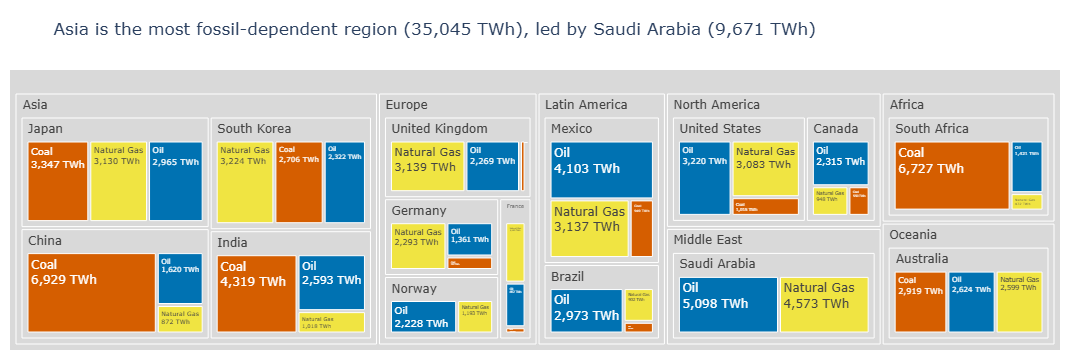

In [7]:
# Task 1 — Treemap: fossil fuel TWh by Region → Country → Source
df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()

# Colour-blind-safe (Okabe-Ito) colours, one per fossil source.
# Parent nodes (Region / Country) show up as '(?)' in plotly -> grey them out.
fossil_colors = {
    'Coal': '#D55E00',         # vermillion
    'Oil': '#0072B2',          # blue
    'Natural Gas': '#F0E442',  # yellow
    '(?)': '#D9D9D9',          # grey parents
}

# Insight title: most fossil-dependent region and country (by absolute TWh)
region_totals = df_fossil.groupby('Region')['TWh'].sum().sort_values(ascending=False)
country_totals = df_fossil.groupby('Country')['TWh'].sum().sort_values(ascending=False)
top_region, top_country = region_totals.index[0], country_totals.index[0]

fig1 = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',
    color='Source',
    color_discrete_map=fossil_colors,
    title=(f"{top_region} is the most fossil-dependent region "
           f"({region_totals.iloc[0]:,.0f} TWh), led by {top_country} "
           f"({country_totals.iloc[0]:,.0f} TWh)"),
)
# TWh in labels and hover, no percentages
fig1.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='%{label}<br>%{value:,.0f} TWh<extra></extra>',
    root_color='#D9D9D9',
)
fig1.update_layout(margin=dict(t=70, l=10, r=10, b=10))
fig1.show()


## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

In [9]:
df_lc = (df.loc[df['Source_Type'] == 'Low-carbon']
           .groupby('Country', as_index=False)['TWh'].sum()
           .sort_values('TWh', ascending=False))
df_lc['All'] = 'Low-carbon'
print(df_lc)

           Country     TWh         All
4           France  7593.0  Low-carbon
9           Norway  6174.0  Low-carbon
2           Canada  5969.0  Low-carbon
1           Brazil  4975.0  Low-carbon
11     South Korea  2484.0  Low-carbon
6            India  1336.0  Low-carbon
13   United States  1137.0  Low-carbon
7            Japan  1012.0  Low-carbon
12  United Kingdom   993.0  Low-carbon
5          Germany   929.0  Low-carbon
8           Mexico   906.0  Low-carbon
3            China   882.0  Low-carbon
10    South Africa   726.0  Low-carbon
0        Australia   448.0  Low-carbon


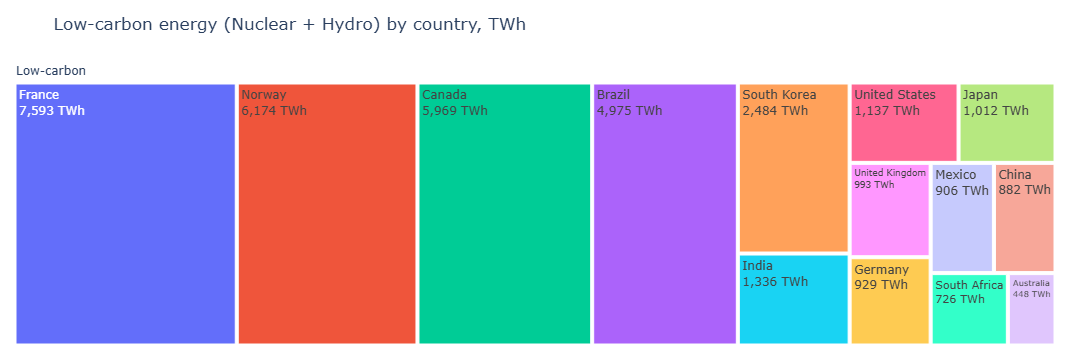

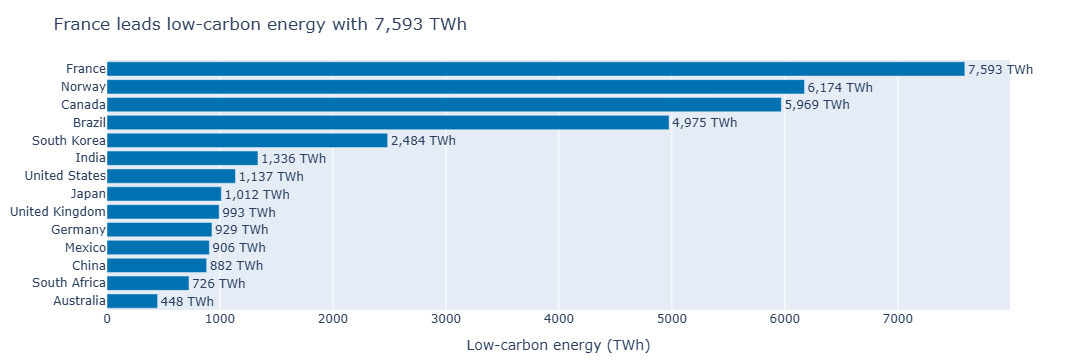

In [10]:
# Task 2 — Low-carbon (Nuclear + Hydro) TWh by country
df_lc = (df.loc[df['Source_Type'] == 'Low-carbon']
           .groupby('Country', as_index=False)['TWh'].sum()
           .sort_values('TWh', ascending=False))
df_lc['All'] = 'Low-carbon'   # dummy root node
lc_blue = '#0072B2'           # colour-blind-safe blue

# --- Treemap ---
fig2a = px.treemap(
    df_lc,
    path=['All', 'Country'],
    values='TWh',
    title='Low-carbon energy (Nuclear + Hydro) by country, TWh',
)
fig2a.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='%{label}<br>%{value:,.0f} TWh<extra></extra>',
)
fig2a.update_layout(margin=dict(t=60, l=10, r=10, b=10))
fig2a.show()

# --- Horizontal bar, sorted (largest on top) ---
leader = df_lc.iloc[0]
fig2b = px.bar(
    df_lc.sort_values('TWh', ascending=True),
    x='TWh', y='Country', orientation='h',
    color_discrete_sequence=[lc_blue],
    title=f"{leader['Country']} leads low-carbon energy with {leader['TWh']:,.0f} TWh",
)
fig2b.update_traces(texttemplate='%{x:,.0f} TWh', textposition='outside', cliponaxis=False)
fig2b.update_layout(xaxis_title='Low-carbon energy (TWh)', yaxis_title=None,
                    margin=dict(t=60, l=10, r=60, b=40))
fig2b.show()

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

The **bar chart**. Bars are all aligned to the same baseline and sorted, so the eye compares *lengths*, which we judge accurately, and the order is read top to bottom without effort. In the treemap the countries are compared by *area* in different shapes and positions, which is much harder to rank precisely, especially for similar-sized or small countries. The treemap does convey "how big is each country's share of the total" at a glance, but for a ranking question the sorted horizontal bar is clearer.


## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

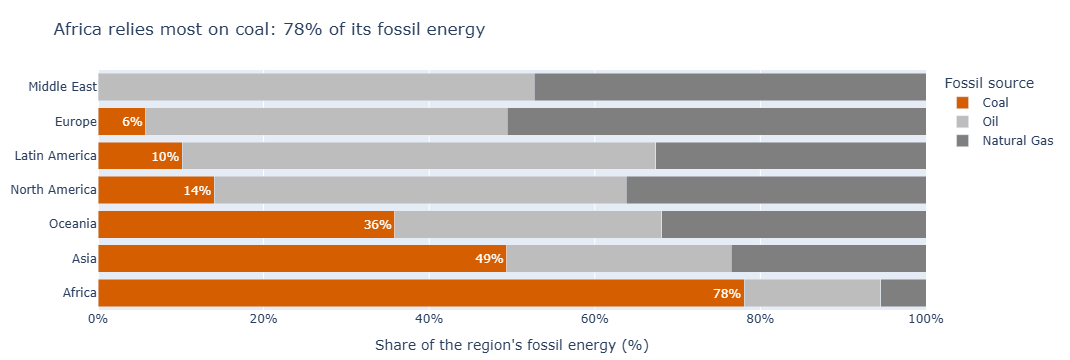

In [11]:
# Task 3 — 100% stacked bar: fossil mix by region
df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()

reg = df_fossil.groupby(['Region', 'Source'], as_index=False)['TWh'].sum()
reg['Share'] = reg['TWh'] / reg.groupby('Region')['TWh'].transform('sum') * 100

# Coal share per region (0 if a region has no coal), for sorting and the title
coal_share = (reg.loc[reg['Source'] == 'Coal']
                 .set_index('Region')['Share']
                 .reindex(reg['Region'].unique(), fill_value=0))

# Plotly draws the first category at the bottom, so ascending order puts the highest coal share on top
region_order = coal_share.sort_values(ascending=True).index.tolist()
top_coal_region = region_order[-1]

source_order = ['Coal', 'Oil', 'Natural Gas']   # Coal first = on the baseline
coal_colour = '#D55E00'                         # must match the Coal colour in Task 1

fig3 = px.bar(
    reg, x='Share', y='Region', color='Source', orientation='h',
    category_orders={'Region': region_order, 'Source': source_order},
    color_discrete_map={'Coal': coal_colour, 'Oil': '#BDBDBD', 'Natural Gas': '#7F7F7F'},
    title=(f"{top_coal_region} relies most on coal: "
           f"{coal_share[top_coal_region]:.0f}% of its fossil energy"),
)

# Percentage labels on the coal segments only
for trace in fig3.data:
    if trace.name == 'Coal':
        trace.text = [f'{v:.0f}%' for v in trace.x]
        trace.textposition = 'inside'
        trace.textfont = dict(color='white')
    else:
        trace.text = None

fig3.update_layout(
    barmode='stack',
    xaxis=dict(title="Share of the region's fossil energy (%)", range=[0, 100], ticksuffix='%'),
    yaxis_title=None,
    legend_title_text='Fossil source',
    margin=dict(t=70, l=10, r=10, b=40),
)
fig3.show()

### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

- **Treemap:** *How much* fossil energy does each country or region burn in absolute terms, and which single country dominates (e.g. which country is the biggest contributor in TWh)? The 100% bar throws the size away, since every region is stretched to the same length.
- **100% stacked bar:** *Which region leans most on coal relative to its own fossil mix*, regardless of its size? Because every bar is normalised to 100% and sorted by coal share, a small region can rank above a huge one, which is hard to read from treemap areas.
